In [1]:
# Import the required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
# Load the dataset

df = pd.read_csv("Heart_Disease_Prediction.csv")


In [5]:
# Display the first five rows
display(df.head())


,Age,Sex,Chest pain type,BP,Cholesterol,FBS over 120,EKG results,Max HR,Exercise angina,ST depression,Slope of ST,Number of vessels fluro,Thallium,Heart Disease
0,70,1,4,130,322,0,2,109,0,2.4,2,3,3,Presence
1,67,0,3,115,564,0,2,160,0,1.6,2,0,7,Absence
2,57,1,2,124,261,0,0,141,0,0.3,1,0,7,Presence
3,64,1,4,128,263,0,0,105,1,0.2,2,1,7,Absence
4,74,0,2,120,269,0,2,121,1,0.2,1,1,3,Absence


In [6]:
# Display dataset dimensions
print("Dataset shape:", df.shape)

Dataset shape: (270, 14)


In [7]:
# Display column names
print("Column names:", df.columns.tolist())

Column names: ['Age', 'Sex', 'Chest pain type', 'BP', 'Cholesterol', 'FBS over 120', 'EKG results', 'Max HR', 'Exercise angina', 'ST depression', 'Slope of ST', 'Number of vessels fluro', 'Thallium', 'Heart Disease']


In [8]:
# Display dataset information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 270 entries, 0 to 269
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Age                      270 non-null    int64  
 1   Sex                      270 non-null    int64  
 2   Chest pain type          270 non-null    int64  
 3   BP                       270 non-null    int64  
 4   Cholesterol              270 non-null    int64  
 5   FBS over 120             270 non-null    int64  
 6   EKG results              270 non-null    int64  
 7   Max HR                   270 non-null    int64  
 8   Exercise angina          270 non-null    int64  
 9   ST depression            270 non-null    float64
 10  Slope of ST              270 non-null    int64  
 11  Number of vessels fluro  270 non-null    int64  
 12  Thallium                 270 non-null    int64  
 13  Heart Disease            270 non-null    object 
dtypes: float64(1), int64(12), 

Phase I — Exploratory Data Analysis (EDA)

In [9]:
# Check missing values
print("Missing values:")
print(df.isnull().sum())

Missing values:
Age                        0
Sex                        0
Chest pain type            0
BP                         0
Cholesterol                0
FBS over 120               0
EKG results                0
Max HR                     0
Exercise angina            0
ST depression              0
Slope of ST                0
Number of vessels fluro    0
Thallium                   0
Heart Disease              0
dtype: int64


In [10]:
# Check duplicate records
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [11]:
# Remove duplicate records
df = df.drop_duplicates().copy()

In [12]:
# Remove extra spaces from column names
df.columns = df.columns.str.strip()

In [13]:
# Display statistical summary
display(df.describe(include="all"))

print("Dataset shape after cleaning:", df.shape)

,Age,Sex,Chest pain type,BP,Cholesterol,FBS over 120,EKG results,Max HR,Exercise angina,ST depression,Slope of ST,Number of vessels fluro,Thallium,Heart Disease
count,270.000000,270.000000,270.000000,270.000000,270.000000,270.000000,270.000000,270.000000,270.000000,270.00000,270.000000,270.000000,270.000000,270
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Absence
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,150
mean,54.433333,0.677778,3.174074,131.344444,249.659259,0.148148,1.022222,149.677778,0.329630,1.05000,1.585185,0.670370,4.696296,NaN
std,9.109067,0.468195,0.950090,17.861608,51.686237,0.355906,0.997891,23.165717,0.470952,1.14521,0.614390,0.943896,1.940659,NaN
min,29.000000,0.000000,1.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.00000,1.000000,0.000000,3.000000,NaN
25%,48.000000,0.000000,3.000000,120.000000,213.000000,0.000000,0.000000,133.000000,0.000000,0.00000,1.000000,0.000000,3.000000,NaN
50%,55.000000,1.000000,3.000000,130.000000,245.000000,0.000000,2.000000,153.500000,0.000000,0.80000,2.000000,0.000000,3.000000,NaN
75%,61.000000,1.000000,4.000000,140.000000,280.000000,0.000000,2.000000,166.000000,1.000000,1.60000,2.000000,1.000000,7.000000,NaN


Dataset shape after cleaning: (270, 14)


In [14]:
# Automatically identify a common Heart Disease target column

target_candidates = [
    "target",
    "HeartDisease",
    "heart_disease",
    "HeartDiseaseorAttack",
    "output",
    "condition",
    "num",
    "TenYearCHD"
]

target_col = next(
    (col for col in target_candidates if col in df.columns),
    None
)

if target_col is None:
    print("Target column not detected.")
    print("Available columns:", df.columns.tolist())
else:
    print("Target column:", target_col)
    print(df[target_col].value_counts(dropna=False))

Target column not detected.
Available columns: ['Age', 'Sex', 'Chest pain type', 'BP', 'Cholesterol', 'FBS over 120', 'EKG results', 'Max HR', 'Exercise angina', 'ST depression', 'Slope of ST', 'Number of vessels fluro', 'Thallium', 'Heart Disease']


Phase II: Data Preprocessing

In [18]:
print("Target column:", target_col)
print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())


Target column: None
Dataset shape: (270, 14)
Columns: ['Age', 'Sex', 'Chest pain type', 'BP', 'Cholesterol', 'FBS over 120', 'EKG results', 'Max HR', 'Exercise angina', 'ST depression', 'Slope of ST', 'Number of vessels fluro', 'Thallium', 'Heart Disease']


In [20]:

# Display all column names in your dataset

print(df.columns.tolist())


['Age', 'Sex', 'Chest pain type', 'BP', 'Cholesterol', 'FBS over 120', 'EKG results', 'Max HR', 'Exercise angina', 'ST depression', 'Slope of ST', 'Number of vessels fluro', 'Thallium', 'Heart Disease']


In [22]:

# Display your dataset columns

print("Columns:", df.columns.tolist())

# Display the first five rows
display(df.head())


Columns: ['Age', 'Sex', 'Chest pain type', 'BP', 'Cholesterol', 'FBS over 120', 'EKG results', 'Max HR', 'Exercise angina', 'ST depression', 'Slope of ST', 'Number of vessels fluro', 'Thallium', 'Heart Disease']


,Age,Sex,Chest pain type,BP,Cholesterol,FBS over 120,EKG results,Max HR,Exercise angina,ST depression,Slope of ST,Number of vessels fluro,Thallium,Heart Disease
0,70,1,4,130,322,0,2,109,0,2.4,2,3,3,Presence
1,67,0,3,115,564,0,2,160,0,1.6,2,0,7,Absence
2,57,1,2,124,261,0,0,141,0,0.3,1,0,7,Presence
3,64,1,4,128,263,0,0,105,1,0.2,2,1,7,Absence
4,74,0,2,120,269,0,2,121,1,0.2,1,1,3,Absence


In [27]:
for col in df.columns:
    print(repr(col))

'Age'
'Sex'
'Chest pain type'
'BP'
'Cholesterol'
'FBS over 120'
'EKG results'
'Max HR'
'Exercise angina'
'ST depression'
'Slope of ST'
'Number of vessels fluro'
'Thallium'
'Heart Disease'


Heart Disease
Absence     150
Presence    120
Name: count, dtype: int64


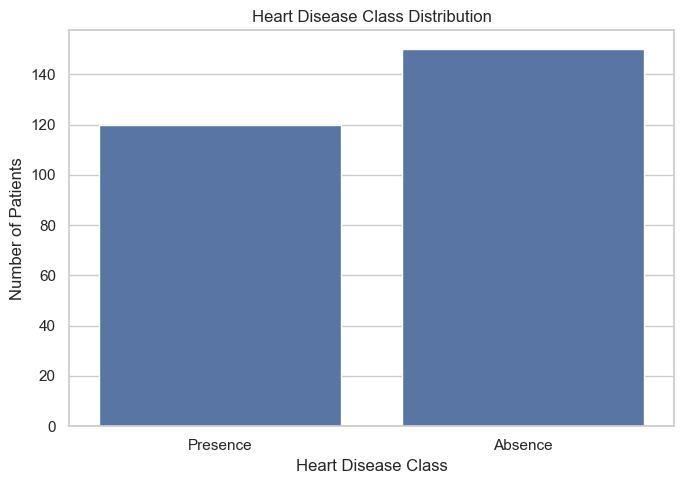

In [29]:

import matplotlib.pyplot as plt
import seaborn as sns

# Check the number of records in each class
print(df["Heart Disease"].value_counts())

# Plot the class distribution
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="Heart Disease")

plt.title("Heart Disease Class Distribution")
plt.xlabel("Heart Disease Class")
plt.ylabel("Number of Patients")

plt.tight_layout()
plt.show()


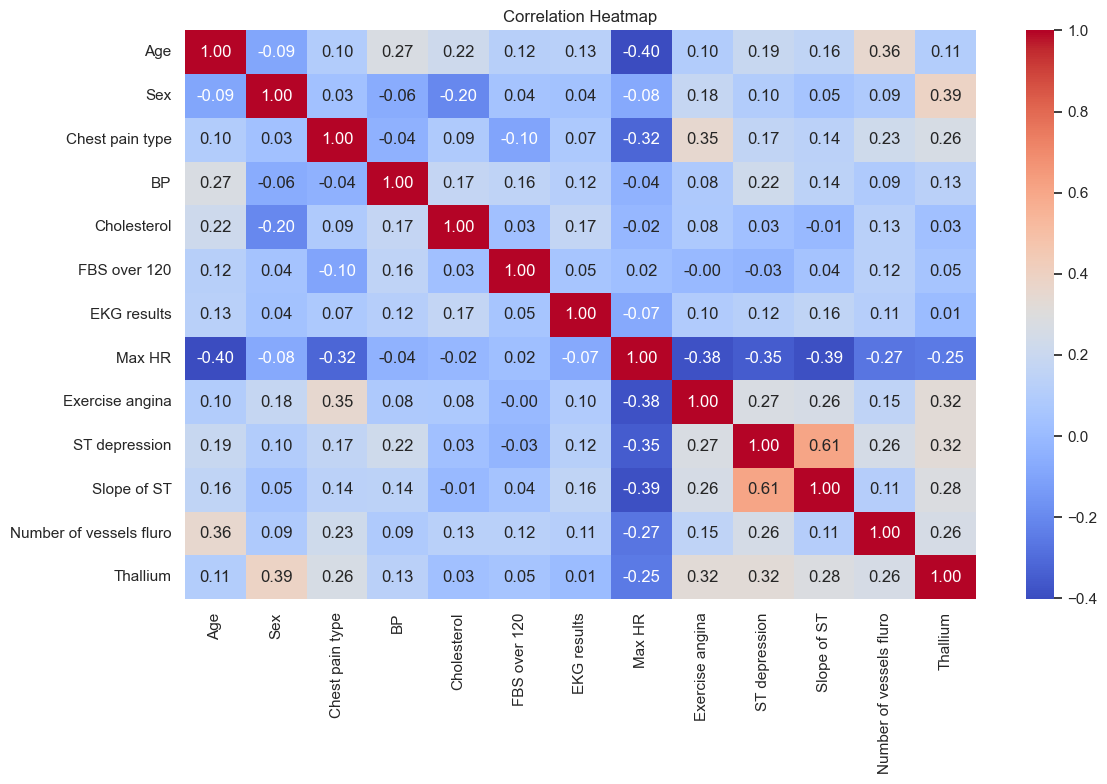

In [30]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    df.select_dtypes(include=np.number).corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

In [34]:
# Set the correct target column name
target_col = "Heart Disease"

# Remove rows where the target value is missing
df = df.dropna(subset=[target_col]).copy()

# Separate input features and target
X = df.drop(columns=[target_col])
y = df[target_col]

# Display the shapes
print("Features:", X.shape)
print("Target:", y.shape)

# Display the number of records in each class
print(y.value_counts())


Features: (270, 13)
Target: (270,)
Heart Disease
Absence     150
Presence    120
Name: count, dtype: int64


In [35]:
numeric_features = X.select_dtypes(include=np.number).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category", "bool", "string"]
).columns.tolist()

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 216
Testing records: 54


Phase III: Random Forest Model Training

In [36]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    random_state=42,
    class_weight="balanced"
)

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", rf_model)
])

model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [37]:
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)

print("Actual values:", y_test.to_list())
print("Predicted values:", y_pred)

Actual values: ['Absence', 'Absence', 'Absence', 'Presence', 'Absence', 'Absence', 'Absence', 'Presence', 'Presence', 'Presence', 'Absence', 'Presence', 'Absence', 'Absence', 'Presence', 'Presence', 'Absence', 'Presence', 'Absence', 'Presence', 'Absence', 'Presence', 'Absence', 'Absence', 'Absence', 'Presence', 'Absence', 'Absence', 'Absence', 'Absence', 'Absence', 'Presence', 'Presence', 'Absence', 'Absence', 'Absence', 'Presence', 'Absence', 'Presence', 'Absence', 'Presence', 'Presence', 'Presence', 'Presence', 'Absence', 'Absence', 'Absence', 'Presence', 'Absence', 'Presence', 'Presence', 'Presence', 'Absence', 'Presence']
Predicted values: ['Absence' 'Absence' 'Absence' 'Presence' 'Absence' 'Absence' 'Absence'
 'Presence' 'Presence' 'Presence' 'Absence' 'Absence' 'Absence' 'Presence'
 'Presence' 'Presence' 'Absence' 'Presence' 'Absence' 'Presence' 'Absence'
 'Presence' 'Absence' 'Presence' 'Absence' 'Presence' 'Absence' 'Absence'
 'Absence' 'Presence' 'Absence' 'Presence' 'Presence

4.1 Accuracy, Precision, Recall and F1-score

In [39]:

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred,
    pos_label="Presence",
    zero_division=0
)

recall = recall_score(
    y_test, y_pred,
    pos_label="Presence",
    zero_division=0
)

f1 = f1_score(
    y_test, y_pred,
    pos_label="Presence",
    zero_division=0
)

print("Random Forest Evaluation Results")
print("--------------------------------")
print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-Score  : {f1:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))


Random Forest Evaluation Results
--------------------------------
Accuracy  : 0.8148
Precision : 0.7692
Recall    : 0.8333
F1-Score  : 0.8000

Classification Report:
              precision    recall  f1-score   support

     Absence       0.86      0.80      0.83        30
    Presence       0.77      0.83      0.80        24

    accuracy                           0.81        54
   macro avg       0.81      0.82      0.81        54
weighted avg       0.82      0.81      0.82        54



4.2 Confusion Matrix

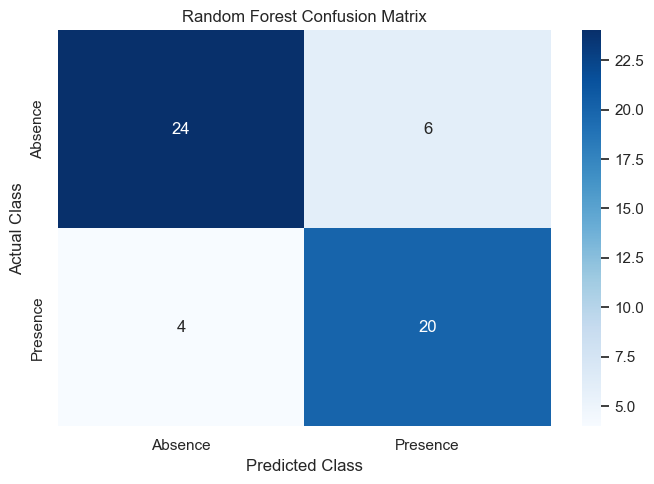

True Negatives: 24
False Positives: 6
False Negatives: 4
True Positives: 20


In [40]:

labels = ["Absence", "Presence"]

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=labels
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

tn, fp, fn, tp = cm.ravel()

print("True Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)


4.3 ROC Curve and AUC Score

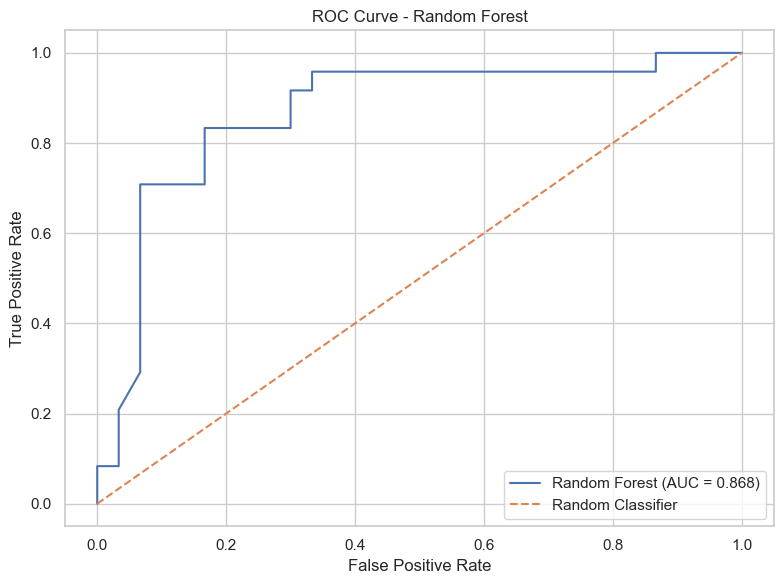

ROC-AUC Score: 0.8681


In [41]:

# Find the probability column corresponding to Presence
positive_index = list(model.classes_).index("Presence")
positive_prob = y_prob[:, positive_index]

# Calculate ROC curve
fpr, tpr, thresholds = roc_curve(
    y_test,
    positive_prob,
    pos_label="Presence"
)

# Calculate AUC
auc_score = roc_auc_score(
    (y_test == "Presence").astype(int),
    positive_prob
)

# Plot ROC curve
plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Random Forest (AUC = {auc_score:.3f})"
)

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.title("ROC Curve - Random Forest")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.tight_layout()
plt.savefig("roc_curve.png", dpi=300, bbox_inches="tight")
plt.show()

print("ROC-AUC Score:", round(auc_score, 4))


Top 15 Important Features:


,Feature,Importance
2,num__Chest pain type,0.137247
7,num__Max HR,0.121340
9,num__ST depression,0.111075
11,num__Number of vessels fluro,0.106485
12,num__Thallium,0.094873
4,num__Cholesterol,0.094829
0,num__Age,0.092224
3,num__BP,0.074267
10,num__Slope of ST,0.061221
1,num__Sex,0.041682


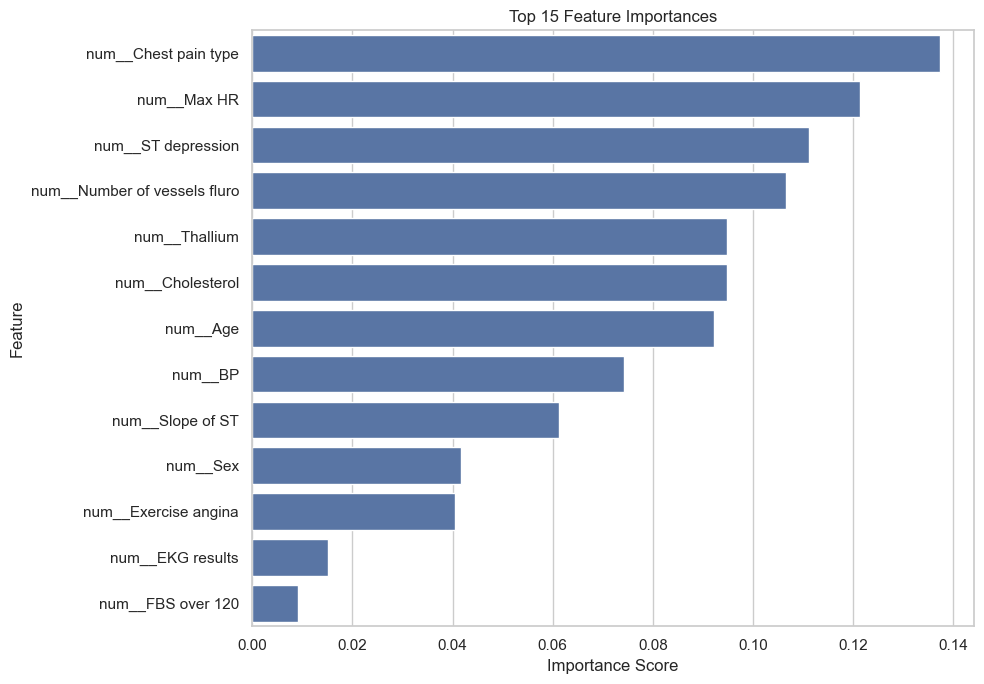

In [42]:

trained_rf = model.named_steps["classifier"]

feature_names = model.named_steps[
    "preprocessor"
].get_feature_names_out()

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": trained_rf.feature_importances_
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print("Top 15 Important Features:")
display(importance_df.head(15))

plt.figure(figsize=(10, 7))

sns.barplot(
    data=importance_df.head(15),
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Feature Importances")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.savefig("feature_importance.png", dpi=300, bbox_inches="tight")
plt.show()


In [43]:

results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "ROC-AUC"
    ],
    "Score": [
        accuracy,
        precision,
        recall,
        f1,
        auc_score
    ]
})

display(results.round(4))

results.to_csv("random_forest_results.csv", index=False)

print("Evaluation results saved successfully!")


,Metric,Score
0,Accuracy,0.8148
1,Precision,0.7692
2,Recall,0.8333
3,F1-Score,0.8000
4,ROC-AUC,0.8681


Evaluation results saved successfully!


In [44]:

print("PROJECT CONCLUSION")
print("===================")

print(f"Accuracy: {accuracy:.2%}")
print(f"Precision: {precision:.2%}")
print(f"Recall: {recall:.2%}")
print(f"F1-Score: {f1:.2%}")
print(f"ROC-AUC: {auc_score:.4f}")

print(f"\nTrue Positives: {tp}")
print(f"True Negatives: {tn}")
print(f"False Positives: {fp}")
print(f"False Negatives: {fn}")

print("\nThe Random Forest model was trained to classify "
      "heart disease records as Absence or Presence.")

print("Precision measures the reliability of positive predictions, "
      "while recall measures how many actual positive records "
      "were correctly identified.")

print("Further improvements could include cross-validation, "
      "hyperparameter tuning, and comparison with Gradient Boosting.")

print("This model is for educational purposes and is not "
      "a clinical diagnostic tool.")


PROJECT CONCLUSION
Accuracy: 81.48%
Precision: 76.92%
Recall: 83.33%
F1-Score: 80.00%
ROC-AUC: 0.8681

True Positives: 20
True Negatives: 24
False Positives: 6
False Negatives: 4

The Random Forest model was trained to classify heart disease records as Absence or Presence.
Precision measures the reliability of positive predictions, while recall measures how many actual positive records were correctly identified.
Further improvements could include cross-validation, hyperparameter tuning, and comparison with Gradient Boosting.
This model is for educational purposes and is not a clinical diagnostic tool.
